# Load in SFINCS data

In [1]:
import xarray as xr
import geopandas as gpd
import numpy as np

In [2]:
his = xr.open_dataset("sfincs_his_extra.nc")

buildings = gpd.read_file("SanFelipe_buildings2.gpkg")
buildings = buildings.to_crs(32616)

In [3]:
print(his)

<xarray.Dataset> Size: 967kB
Dimensions:        (stations: 176, time: 433, runtime: 1)
Coordinates:
    station_id     (stations) float32 704B ...
    station_name   (stations) |S256 45kB ...
    point_x        (stations) float32 704B ...
    point_y        (stations) float32 704B ...
  * time           (time) datetime64[ns] 3kB 2024-02-04 ... 2024-02-07
Dimensions without coordinates: stations, runtime
Data variables:
    inp            int32 4B ...
    station_x      (stations) float32 704B ...
    station_y      (stations) float32 704B ...
    crs            int32 4B ...
    point_zb       (stations) float32 704B ...
    point_zs       (time, stations) float32 305kB ...
    point_h        (time, stations) float32 305kB ...
    point_qinf     (time, stations) float32 305kB ...
    total_runtime  (runtime) float32 4B ...
    average_dt     (runtime) float32 4B ...
    status         (runtime) float32 4B ...
Attributes:
    Conventions:                         CF-1.8
    featureType:  

In [4]:
import pandas as pd

# add maximum inundation level
hmax = his["point_h"].max(dim="time")

# inundation time (10 min time step)
dt_hours = 10 / 60
duration_h = (his["point_h"] > 0).sum(dim="time") * dt_hours

# combined dataframe
df = pd.DataFrame({
    "station_name": [
        n.decode() if isinstance(n, bytes) else n
        for n in his.station_name.values
    ],
    "x": his.point_x.values,
    "y": his.point_y.values,
    "hmax": hmax.values,
    "duration_h": duration_h.values
})

print(df.head())

                                        station_name             x  \
0  Main street                                   ...  372401.71875   
1  Station_SF                                    ...  374195.18750   
2  C11-04                                        ...  372280.06250   
3  C14-02                                        ...  372292.31250   
4  C14-01                                        ...  372299.28125   

            y      hmax  duration_h  
0  2385237.50  0.140292   11.666667  
1  2385951.50  3.030661   72.166667  
2  2385463.75  0.000000    0.000000  
3  2385502.75  0.015637    4.166667  
4  2385532.00  0.054720    5.500000  


# Maximum inundation level

In [5]:
print(df[df["hmax"] > 0.75])

#be careful, manually adjust treshold value of 0.75 m 
#Station_SF is located in the Mangrove (hmax > 2.5 m) and is removed from the data in this step

                                        station_name            x          y  \
1  Station_SF                                    ...  374195.1875  2385951.5   

       hmax  duration_h  
1  3.030661   72.166667  


<Axes: >

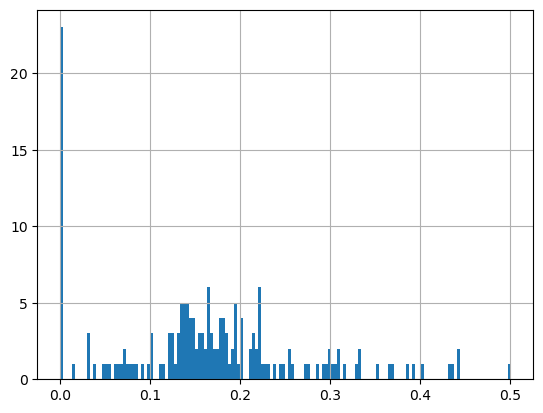

In [6]:
df = df[df["hmax"] <= 0.75]
df["hmax"].hist(bins=150)

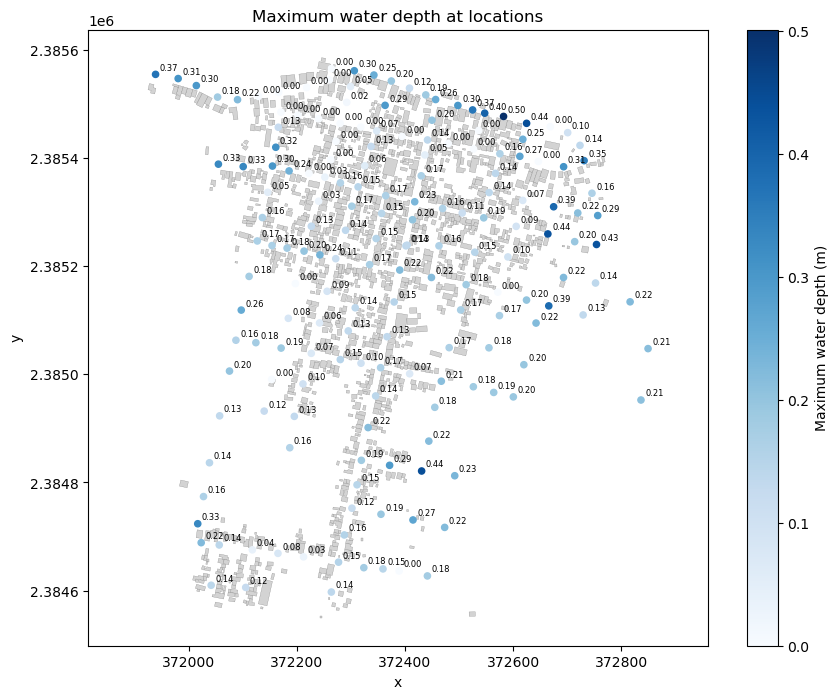

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# gebouwen
buildings.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="grey",
    linewidth=0.2
)

sc = plt.scatter(
    df["x"],
    df["y"],
    c=df["hmax"],
    cmap="Blues",
    s=20
)

for _, row in df.iterrows():
    plt.annotate(
        f"{row['hmax']:.2f}",
        (row["x"], row["y"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6
    )

plt.colorbar(sc, label="Maximum water depth (m)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Maximum water depth at locations")

plt.axis("equal")
plt.show()

# Maximum inundation time

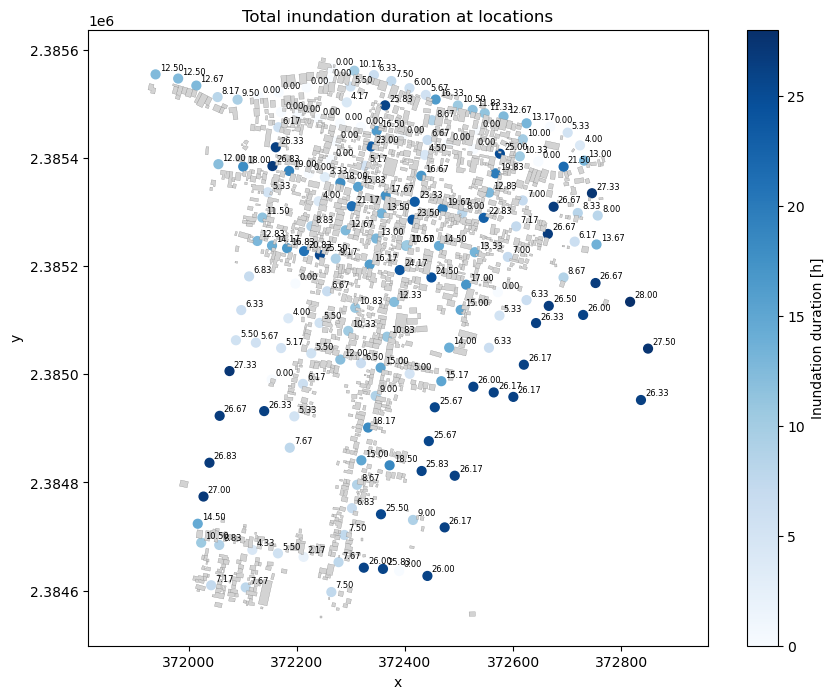

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
sc = plt.scatter(
    df["x"],
    df["y"],
    c=df["duration_h"],
    cmap="Blues",
    s=40
)
# gebouwen
buildings.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="grey",
    linewidth=0.2
)

for _, row in df.iterrows():
    plt.annotate(
        f"{row['duration_h']:.2f}",
        (row["x"], row["y"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6
    )

plt.colorbar(sc, label="Inundation duration [h]")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Total inundation duration at locations")
plt.axis("equal")
plt.show()

# Hazard score

In [9]:
# normalisation
H = df["hmax"] / df["hmax"].max()
T = (df["duration_h"] / df["duration_h"].max())**2

# hazardscore
df["hazard"] = 0.7 * H + 0.3 * T

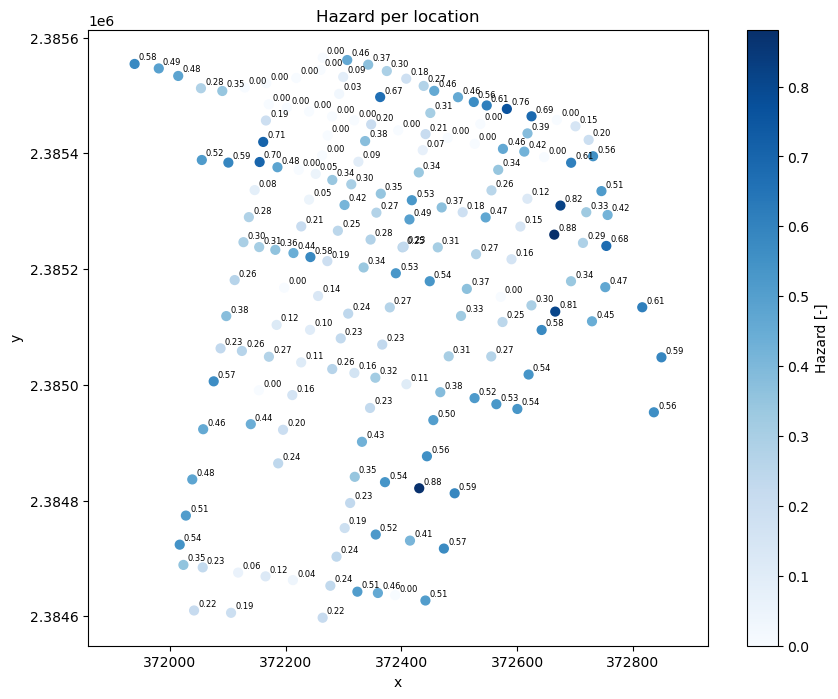

In [10]:
plt.figure(figsize=(10, 8))

sc = plt.scatter(
    df["x"],
    df["y"],
    c=df["hazard"],
    cmap="Blues",
    s=40
)

buildings.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="grey",
    linewidth=0.2
)

for _, row in df.iterrows():
    plt.annotate(
        f"{row['hazard']:.2f}",
        (row["x"], row["y"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6
    )

plt.colorbar(sc, label="Hazard [-]")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Hazard per location")
plt.axis("equal")
plt.show()

# K-Means Clustering

## Assign hydraulic properties to buildings

In [11]:
import geopandas as gpd

# markers into GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["x"], df["y"]),
    crs=buildings.crs  
)

In [12]:
buildings_nn = gpd.sjoin_nearest(
    buildings,
    stations_gdf[
        ["station_name", "hmax", "duration_h", "geometry"]
    ],
    how="left"
)

In [13]:
print(buildings_nn[["hmax", "duration_h"]].head())

       hmax  duration_h
0  0.161867   14.500000
1  0.099438    7.000000
2  0.140292   11.666667
3  0.147316   13.333333
4  0.221574   24.166667


In [14]:
buildings_nn = gpd.sjoin_nearest(
    buildings,
    stations_gdf[
        ["station_name", "hmax", "duration_h", "geometry"]
    ],
    how="left",
    distance_col="distance"
)

<Axes: >

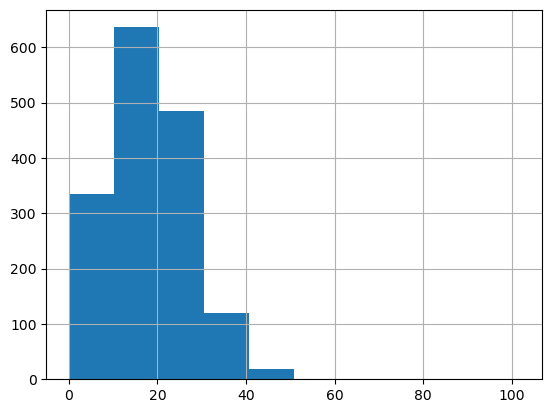

In [15]:
buildings_nn["distance"].describe()
buildings_nn["distance"].hist()

In [16]:
buildings_nn = buildings_nn[buildings_nn["distance"] <= 50].copy()

In [17]:
print("Total amount of buildings:", len(buildings_nn))

print(
    "Buildings with hmax > 0:",
    (buildings_nn["hmax"] > 0).sum()
)

Total amount of buildings: 1591
Buildings with hmax > 0: 1368


In [18]:
bf = buildings_nn[
    buildings_nn["hmax"] > 0
].copy()

## Start K-Means clustering by exploring k-values

In [19]:
bf["h_norm"] = bf["hmax"] / bf["hmax"].max()
bf["t_norm"] = bf["duration_h"] / bf["duration_h"].max()

In [20]:
print(bf[["h_norm", "t_norm"]].describe())

            h_norm       t_norm
count  1368.000000  1368.000000
mean      0.319958     0.467007
std       0.155279     0.236956
min       0.031226     0.079268
25%       0.246155     0.274390
50%       0.294173     0.426829
75%       0.365006     0.621951
max       1.000000     1.000000


In [21]:
from sklearn.cluster import KMeans
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X = bf[["h_norm", "t_norm"]]


c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memor

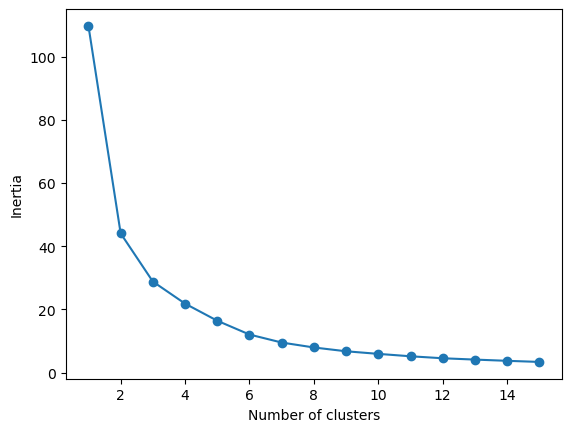

In [22]:
inertia = []
silhouette = []

for k in range(1,16):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    km.fit(X)

    inertia.append(km.inertia_)

    score = silhouette_score(X, km.labels_) if k > 1 else float("nan")
    silhouette.append(score)

plt.plot(range(1,16), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

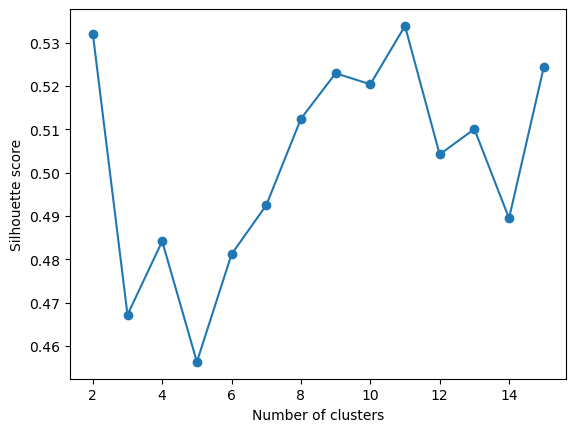

In [23]:
plt.plot(range(1,16), silhouette, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.show()

In [24]:
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

results = []

for k in range(2, 16):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = km.fit_predict(X)

    bf_temp = bf.copy()
    bf_temp["cluster"] = labels

    # standaardafwijking per cluster
    cluster_stats = (
        bf_temp.groupby("cluster")
        .agg({
            "hmax": "std",
            "duration_h": "std"
        })
    )

    results.append({
        "k": k,
        "mean_h_std": cluster_stats["hmax"].mean(),
        "mean_duration_std": cluster_stats["duration_h"].mean(),
        "max_h_std": cluster_stats["hmax"].max(),
        "max_duration_std": cluster_stats["duration_h"].max()
    })

results = pd.DataFrame(results)

print(results)

c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memor

     k  mean_h_std  mean_duration_std  max_h_std  max_duration_std
0    2    0.063855           3.662160   0.077809          4.296323
1    3    0.059859           2.449233   0.083434          3.244540
2    4    0.046727           3.063032   0.059865          5.447873
3    5    0.043651           2.116984   0.078407          3.381566
4    6    0.038171           1.978281   0.060511          3.338009
5    7    0.034993           1.638741   0.060511          3.381566
6    8    0.032773           1.534060   0.060511          2.941820
7    9    0.033026           1.119575   0.062499          1.577901
8   10    0.031057           1.060193   0.062499          1.603640
9   11    0.024583           1.014234   0.061144          1.336752
10  12    0.023705           0.921346   0.061144          1.480623
11  13    0.021783           0.894175   0.055846          1.616737
12  14    0.022242           0.859459   0.053257          1.214982
13  15    0.019117           0.892477   0.040327          1.43

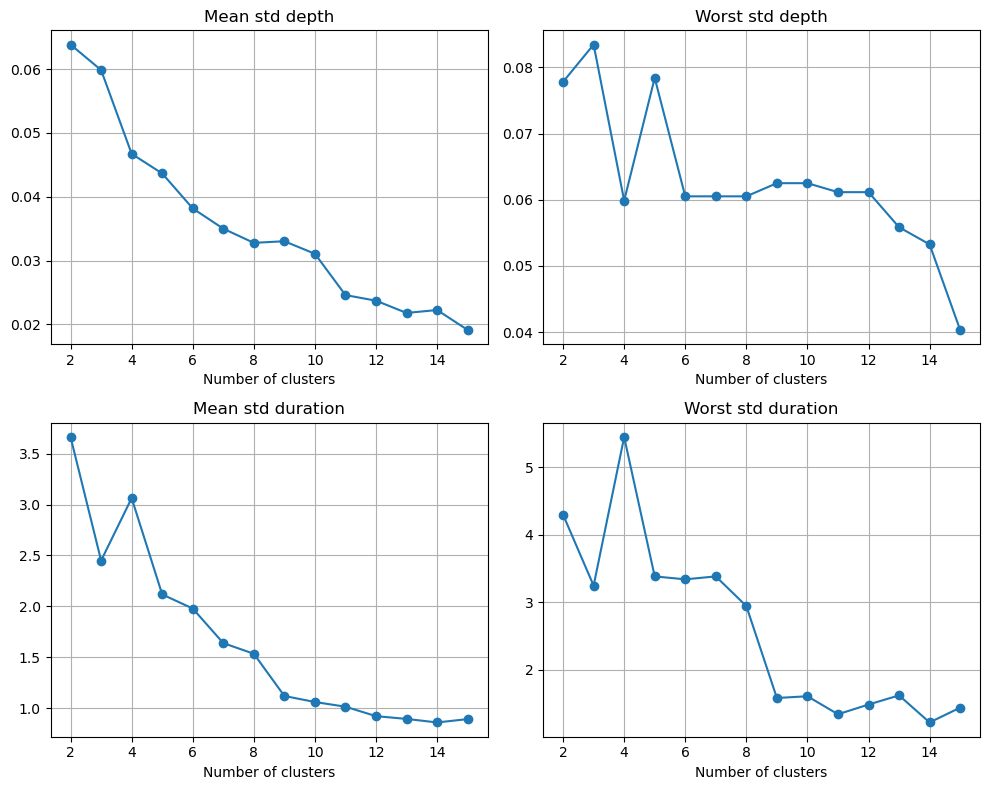

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0,0].plot(results["k"], results["mean_h_std"], marker="o")
ax[0,0].set_title("Mean std depth")

ax[0,1].plot(results["k"], results["max_h_std"], marker="o")
ax[0,1].set_title("Worst std depth")

ax[1,0].plot(results["k"], results["mean_duration_std"], marker="o")
ax[1,0].set_title("Mean std duration")

ax[1,1].plot(results["k"], results["max_duration_std"], marker="o")
ax[1,1].set_title("Worst std duration")

for axi in ax.flat:
    axi.set_xlabel("Number of clusters")
    axi.grid(True)

plt.tight_layout()
plt.show()

## After deciding the amount of clusters (k), the K-Means clustering starts here

In [26]:
# taking into account only flooded buildings
bf = buildings_nn[buildings_nn["hmax"] > 0.01].copy()

# normalisation
bf["h_norm"] = bf["hmax"] / bf["hmax"].max()
bf["t_norm"] = bf["duration_h"] / bf["duration_h"].max()

X = bf[["h_norm", "t_norm"]]

# clustering
k = 10

km = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

bf["cluster"] = km.fit_predict(X)

buildings_nn["cluster"] = -1
buildings_nn.loc[bf.index, "cluster"] = bf["cluster"]

print("Amount of buildings per cluster:")
print(
    bf.groupby("cluster")
    .size()
    .sort_values(ascending=False)
)

c:\Users\bjarn\tudelft-conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


Amount of buildings per cluster:
cluster
9    358
3    236
1    214
0    184
8    118
5     73
4     62
2     51
7     46
6     26
dtype: int64


In [27]:
# mean characterstics per cluster
cluster_order = (
    bf.groupby("cluster")
    .agg({
        "hmax": "mean",
        "duration_h": "mean"
    })
)

# score for ranking
cluster_order["severity"] = (
    cluster_order["hmax"] / cluster_order["hmax"].max()
    + cluster_order["duration_h"] / cluster_order["duration_h"].max()
)

# sort from low hazard to high hazard
cluster_order = cluster_order.sort_values("severity")

# mapping 
mapping = {
    old: new
    for new, old in enumerate(cluster_order.index, start=1)
}

print(mapping)

{0: 1, 9: 2, 3: 3, 4: 4, 1: 5, 5: 6, 8: 7, 6: 8, 7: 9, 2: 10}


In [28]:
bf["cluster"] = bf["cluster"].map(mapping)

buildings_nn.loc[bf.index, "cluster"] = bf["cluster"]

In [29]:
# cluster properties

cluster_stats = (
    bf.groupby("cluster")
    .agg({
        "hmax": ["min", "mean", "max", "std"],
        "duration_h": ["min", "mean", "max", "std"],
        "cluster": "size"
    })
)

print(cluster_stats)

             hmax                               duration_h             \
              min      mean       max       std        min       mean   
cluster                                                                 
1        0.015637  0.054665  0.100266  0.017308   2.166667   4.839674   
2        0.085429  0.127332  0.201488  0.022808   4.000000   7.608007   
3        0.133239  0.144785  0.167153  0.009630  10.333333  12.149011   
4        0.195825  0.251005  0.308844  0.036066   6.333333   9.706989   
5        0.071933  0.171340  0.216752  0.028043  14.166667  16.217290   
6        0.125538  0.156572  0.198259  0.021103  19.666667  20.691781   
7        0.138231  0.203897  0.237904  0.024740  22.833333  24.283898   
8        0.329521  0.388102  0.500780  0.055846  11.333333  12.448718   
9        0.244581  0.296042  0.333179  0.032529  16.333333  18.742754   
10       0.294619  0.352026  0.443434  0.062499  25.833333  26.408497   

                             cluster  
           

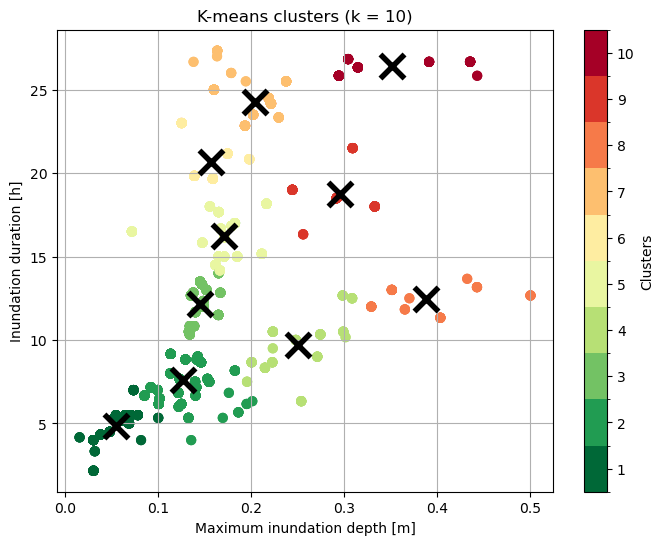

In [30]:
# scatterplot hmax vs duration

from matplotlib.colors import ListedColormap
import numpy as np

colors = plt.cm.RdYlGn_r(np.linspace(0.00, 1.0, 10))
cmap10 = ListedColormap(colors)


fig, ax = plt.subplots(figsize=(8,6))
from matplotlib.colors import BoundaryNorm

bounds = np.arange(0.5, 11.5, 1)
norm = BoundaryNorm(bounds, cmap10.N)

sc = ax.scatter(
    bf["hmax"],
    bf["duration_h"],
    c=bf["cluster"],
    cmap=cmap10,
    norm=norm,
    s=40
)

cbar = fig.colorbar(
    sc,
    ax=ax,
    ticks=np.arange(1, 11),
    boundaries=bounds
)

cbar.set_label("Cluster")

sc = ax.scatter(
    bf["hmax"],
    bf["duration_h"],
    c=bf["cluster"],
    cmap=cmap10,
    s=40
)

cluster_means = (
    bf.groupby("cluster")[["hmax", "duration_h"]]
      .mean()
      .reset_index()
)

plt.scatter(
    cluster_means["hmax"],
    cluster_means["duration_h"],
    marker="x",
    c="black",
    s=300,
    linewidths=4,
    zorder=10
)

ax.set_xlabel("Maximum inundation depth [m]")
ax.set_ylabel("Inundation duration [h]")
ax.set_title("K-means clusters (k = 10)")
ax.grid(True)


cbar.set_label("Clusters")
plt.show()

## Map the results

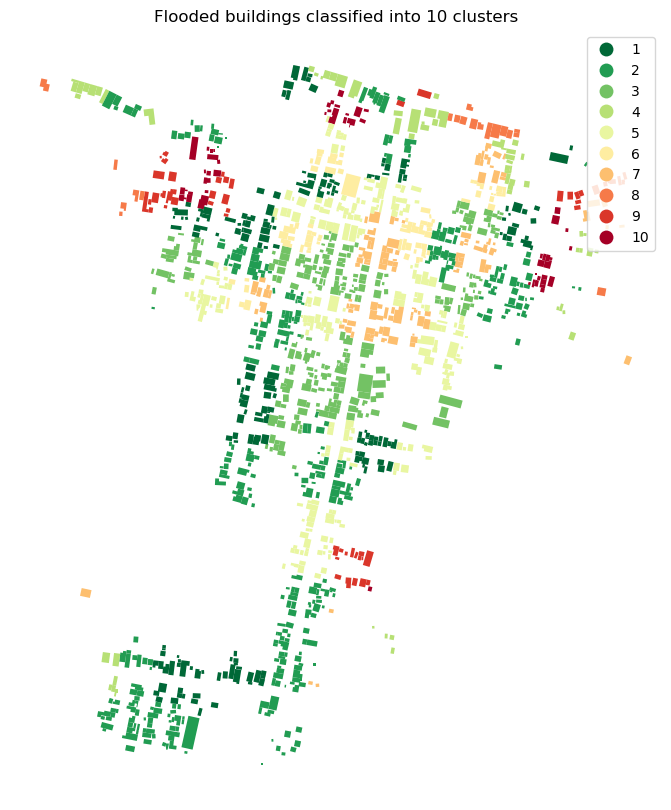

In [31]:
fig, ax = plt.subplots(figsize=(10,10))

bf.plot(
    column="cluster",
    cmap=cmap10,
    categorical=True,
    legend=True,
    linewidth=0.2,
    ax=ax
)

ax.set_title("Flooded buildings classified into 10 clusters")
ax.set_axis_off()

plt.show()

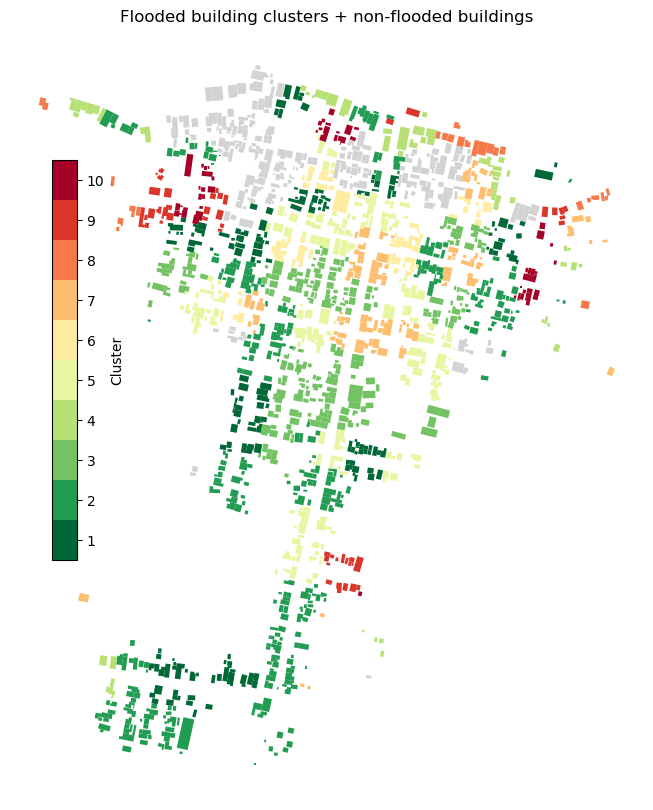

In [32]:
fig, ax = plt.subplots(figsize=(10,10))

# not flooded buildings
buildings_nn[
    buildings_nn["cluster"] == -1
].plot(
    ax=ax,
    color="lightgrey",
    linewidth=0.2
)

# flooded buildings
buildings_nn[
    buildings_nn["cluster"] >= 0
].plot(
    column="cluster",
    cmap=cmap10,
    linewidth=0.2,
    ax=ax,
    legend=False
)

# make space for colorbar
fig.subplots_adjust(left=0.15)

cax = fig.add_axes([0.25, 0.35, 0.025, 0.4])

sm = plt.cm.ScalarMappable(
    cmap=cmap10,
    norm=plt.Normalize(vmin=0.5, vmax=10.5)
)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)

# clusters as discrete values
cbar.set_ticks(range(1,11))
cbar.set_ticklabels(range(1,11))
cbar.set_label("Cluster")

ax.set_title("Flooded building clusters + non-flooded buildings")
ax.set_axis_off()

plt.show()

## Make colorbar for in final map

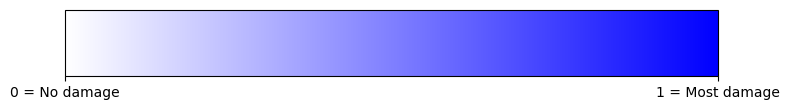

In [33]:
import matplotlib.colors as mcolors
import matplotlib.colorbar as colorbar

fig, ax = plt.subplots(figsize=(8, 1.2))

# wit -> blauw (#0000FF)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "damage",
    ["#FFFFFF", "#0000FF"]
)

norm = plt.Normalize(vmin=0, vmax=1)

cb = colorbar.ColorbarBase(
    ax,
    cmap=cmap,
    norm=norm,
    orientation="horizontal"
)

cb.set_ticks([0, 1])
cb.set_ticklabels(["0 = No damage", "1 = Most damage"])

plt.tight_layout()
plt.show()